# 01 Explore air quality (OpenAQ v3)
Goal: facts about the raw feed + a decision for each. Run cells top to bottom; read each output.

## 1. Setup: load the key and one small helper

In [1]:
import os
from datetime import UTC, datetime

import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import requests
from dotenv import load_dotenv

load_dotenv("../.env")  # the notebook sits in notebooks/, the .env one level up
HEADERS = {"X-API-Key": os.environ["OPENAQ_API_KEY"]}
BASE = "https://api.openaq.org/v3"


def get(path, **params):
    response = requests.get(f"{BASE}/{path}", headers=HEADERS, params=params, timeout=30)
    response.raise_for_status()
    return response.json()

## 2. Look at one raw item before doing anything to it

In [2]:
payload = get("locations", coordinates="28.6139,77.2090", radius=25000, limit=1000)
print(payload["meta"])
payload["results"][0]

{'name': 'openaq-api', 'website': '/', 'page': 1, 'limit': 1000, 'found': 97}


{'id': 13,
 'name': 'Delhi Technological University, Delhi - CPCB',
 'locality': None,
 'timezone': 'Asia/Kolkata',
 'country': {'id': 9, 'code': 'IN', 'name': 'India'},
 'owner': {'id': 4, 'name': 'Unknown Governmental Organization'},
 'provider': {'id': 168, 'name': 'CPCB'},
 'isMobile': False,
 'isMonitor': True,
 'instruments': [{'id': 2, 'name': 'Government Monitor'}],
 'sensors': [{'id': 13866,
   'name': 'no2 µg/m³',
   'parameter': {'id': 5,
    'name': 'no2',
    'units': 'µg/m³',
    'displayName': 'NO₂ mass'}},
  {'id': 24,
   'name': 'o3 µg/m³',
   'parameter': {'id': 3,
    'name': 'o3',
    'units': 'µg/m³',
    'displayName': 'O₃ mass'}},
  {'id': 13864,
   'name': 'pm25 µg/m³',
   'parameter': {'id': 2,
    'name': 'pm25',
    'units': 'µg/m³',
    'displayName': 'PM2.5'}}],
 'coordinates': {'latitude': 28.744, 'longitude': 77.12},
 'licenses': None,
 'bounds': [77.12, 28.744, 77.12, 28.744],
 'distance': 16839.73364921,
 'datetimeFirst': {'utc': '2016-11-02T19:00:00Z',

## 3. Flatten the stations into a table

In [3]:
stations = pd.json_normalize(payload["results"])[
    [
        "id",
        "name",
        "provider.name",
        "isMonitor",
        "coordinates.latitude",
        "coordinates.longitude",
        "datetimeLast.utc",
    ]
].rename(columns={"provider.name": "provider", "datetimeLast.utc": "last_seen"})
stations["last_seen"] = pd.to_datetime(stations["last_seen"], utc=True)
stations["days_silent"] = (pd.Timestamp.now(tz="UTC") - stations["last_seen"]).dt.days
stations.sort_values("days_silent").head(20)

,id,name,provider,isMonitor,coordinates.latitude,coordinates.longitude,last_seen,days_silent
49,6929,"Major Dhyan Chand National Stadium, Delhi - DPCC",CPCB,True,28.611281,77.237738,2026-11-12 05:15:00+00:00,0.0
68,8475,"Sonia Vihar, Delhi - DPCC",CPCB,True,28.710508,77.249485,2026-11-12 05:30:00+00:00,0.0
67,8472,"Bawana, Delhi - DPCC",CPCB,True,28.776200,77.051074,2026-11-12 05:15:00+00:00,0.0
66,8365,"Nehru Nagar, Delhi - DPCC",CPCB,True,28.567890,77.250515,2026-11-12 05:30:00+00:00,0.0
65,8239,"Okhla Phase-2, Delhi - DPCC",CPCB,True,28.530785,77.271255,2026-11-12 05:30:00+00:00,0.0
64,8235,"Jahangirpuri, Delhi - DPCC",CPCB,True,28.732820,77.170633,2026-11-12 05:15:00+00:00,0.0
63,8118,New Delhi,AirNow,True,28.635760,77.224450,2026-11-12 06:30:00+00:00,0.0
59,7005,"Loni, Ghaziabad - UPPCB",CPCB,True,28.757294,77.278792,2026-11-12 05:15:00+00:00,0.0
58,6988,"Sector-116, Noida - UPPCB",CPCB,True,28.569230,77.393848,2026-11-12 05:30:00+00:00,0.0
69,8915,"Wazirpur, Delhi - DPCC",CPCB,True,28.699793,77.165453,2026-11-12 05:30:00+00:00,0.0


## 4. Is the feed alive? Stations by provider and staleness
If nearly every reference monitor is silent for days, wait a day. If it persists, switch to Open-Meteo Air Quality (only `extract/openaq.py` changes).

In [4]:
stations.groupby(["provider", "isMonitor"]).agg(
    stations=("id", "count"),
    freshest_days=("days_silent", "min"),
    stalest_days=("days_silent", "max"),
)

stations  freshest_days  stalest_days
provider          isMonitor                                       
AirGradient       False             7            0.0         231.0
AirNow            True              1            0.0           0.0
CPCB              False             1          151.0         151.0
                  True             56            0.0        3185.0
N/A               False             8            0.0           0.0
StateAir NewDelhi True              1         3654.0        3654.0
caaqm             True             23         1473.0        3106.0

## 5. Hourly PM2.5 for one active station, across Diwali

In [5]:
active = stations[stations["isMonitor"] & (stations["days_silent"] <= 2)]
location = next(item for item in payload["results"] if item["id"] == active.iloc[0]["id"])

# FINDING: one location can hold several pm25 sensors, old dead ones (2016-2018) next to the live one.
# The /locations list has no per-sensor dates, so ask /sensors and keep the most recently seen.
sensors = get(f"locations/{location['id']}/sensors")["results"]
pm25 = [s for s in sensors if s["parameter"]["name"] == "pm25"]
for s in pm25:
    print(s["id"], (s["datetimeLast"] or {}).get("utc"))
sensor = max(pm25, key=lambda s: (s["datetimeLast"] or {}).get("utc", ""))

start = datetime(2026, 11, 1, tzinfo=UTC)
end = datetime(2026, 11, 12, tzinfo=UTC)
hours = get(
    f"sensors/{sensor['id']}/hours",
    datetime_from=start.strftime("%Y-%m-%dT%H:%M:%SZ"),
    datetime_to=end.strftime("%Y-%m-%dT%H:%M:%SZ"),
    limit=1000,
)
print(location["name"], "| readings:", len(hours["results"]))
hours["results"][0]

12234787 2026-11-12T05:30:00Z
35 2018-02-21T21:15:00Z
R K Puram, Delhi - DPCC | readings: 234


{'value': 151.0,
 'flagInfo': {'hasFlags': False},
 'parameter': {'id': 2, 'name': 'pm25', 'units': 'µg/m³', 'displayName': None},
 'period': {'label': '1hour',
  'interval': '01:00:00',
  'datetimeFrom': {'utc': '2026-10-31T23:30:00Z',
   'local': '2026-11-01T05:00:00+05:30'},
  'datetimeTo': {'utc': '2026-11-01T00:30:00Z',
   'local': '2026-11-01T06:00:00+05:30'}},
 'coordinates': None,
 'summary': {'min': 151.0,
  'q02': 151.0,
  'q25': 151.0,
  'median': 151.0,
  'q75': 151.0,
  'q98': 151.0,
  'max': 151.0,
  'avg': 151.0,
  'sd': 0.0},
 'coverage': {'expectedCount': 4,
  'expectedInterval': '01:00:00',
  'observedCount': 4,
  'observedInterval': '01:00:00',
  'percentComplete': 100.0,
  'percentCoverage': 100.0,
  'datetimeFrom': {'utc': '2026-10-31T22:45:00Z',
   'local': '2026-11-01T04:15:00+05:30'},
  'datetimeTo': {'utc': '2026-11-01T00:30:00Z',
   'local': '2026-11-01T06:00:00+05:30'}}}

## 6. Same table in pandas and in Polars

In [6]:
records = [
    {"measured_at": item["period"]["datetimeFrom"]["utc"], "value": item["value"]}
    for item in hours["results"]
]
pm_pd = pd.DataFrame(records)
pm_pd["measured_at"] = pd.to_datetime(pm_pd["measured_at"], utc=True)

pm_pl = pl.DataFrame(records).with_columns(
    pl.col("measured_at").str.to_datetime("%Y-%m-%dT%H:%M:%S%#z")
)
display(pm_pd.head(3), pm_pl.head(3))

,measured_at,value
0,2026-10-31 23:30:00+00:00,151.0
1,2026-11-01 00:30:00+00:00,151.0
2,2026-11-01 01:30:00+00:00,145.0


measured_at,value
"datetime[μs, UTC]",f64
2026-10-31 23:30:00 UTC,151.0
2026-11-01 00:30:00 UTC,151.0
2026-11-01 01:30:00 UTC,145.0


## 7. Quality checks: gaps, duplicates, impossible values, ceilings

In [7]:
expected = int((end - start).total_seconds() // 3600)
print("hours expected:", expected, "| received:", len(pm_pd))
print("duplicate hours:", pm_pd["measured_at"].duplicated().sum())
print("missing values:", pm_pd["value"].isna().sum())
print("negative values:", (pm_pd["value"] < 0).sum())
print(pm_pd["value"].describe())

# The same maximum repeated many times means the instrument hit its ceiling.
pm_pd["value"].value_counts().sort_index(ascending=False).head(5)

hours expected: 264 | received: 234
duplicate hours: 0
missing values: 0
negative values: 0
count    234.000000
mean     246.480769
std      117.238963
min       72.000000
25%      169.250000
50%      222.000000
75%      309.750000
max      924.000000
Name: value, dtype: float64


value
924.0    1
714.0    1
632.0    1
616.0    1
609.0    1
Name: count, dtype: int64

## 8. Timezone check: the Diwali peak must land on the night of 8 November, India time
If it lands in the afternoon, a timezone is wrong.

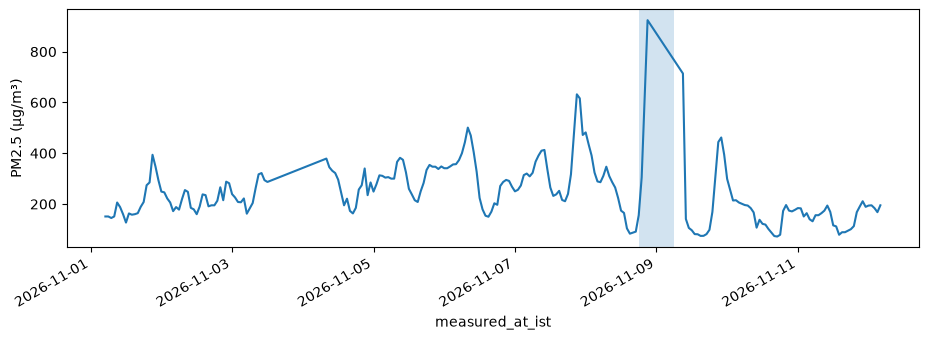

measured_at,value,measured_at_ist
"datetime[μs, UTC]",f64,"datetime[μs, Asia/Kolkata]"
2026-11-08 15:30:00 UTC,924.0,2026-11-08 21:00:00 IST
2026-11-09 03:30:00 UTC,714.0,2026-11-09 09:00:00 IST
2026-11-07 15:30:00 UTC,632.0,2026-11-07 21:00:00 IST


In [8]:
pm_pd["measured_at_ist"] = pm_pd["measured_at"].dt.tz_convert("Asia/Kolkata")
ax = pm_pd.set_index("measured_at_ist")["value"].plot(figsize=(11, 3.5))
ax.axvspan(
    pd.Timestamp("2026-11-08 18:00", tz="Asia/Kolkata"),
    pd.Timestamp("2026-11-09 06:00", tz="Asia/Kolkata"),
    alpha=0.2,
)
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

# The same question in Polars: the three worst hours, in India time
pm_pl.with_columns(
    pl.col("measured_at").dt.convert_time_zone("Asia/Kolkata").alias("measured_at_ist")
).sort("value", descending=True).head(3)

## Findings → decisions (the real product of step 3)
Confirm each row against your own output; add rows for anything new. Full detail: `.field-guide/DATASETS.md`.

| What we saw | Decision | Where it ends up |
|---|---|---|
| Locations mix reference monitors and low-cost sensors | Keep only `isMonitor` locations | extract/openaq.py |
| Some stations silent for weeks (caaqm, StateAir: years) | Skip stations silent > 7 days | config.py |
| One location holds several pm25 sensors; old ones dead since 2018 | Pick the pm25 sensor with the latest `datetimeLast` | extract/openaq.py |
| Hourly buckets start at :30 UTC (= on the hour IST); each has `coverage.percentComplete` | Keep `datetimeFrom.utc` as the hour key; keep coverage | transform/ |
| 234 of 264 hours received at R K Puram (11% missing) | Do not fill gaps; city mean needs 5+ stations | marts |
| Nulls, negative error codes, values above instrument range | Drop outside valid range per pollutant | config.py, transform/ |
| Same hour can arrive twice | Keep last copy per sensor+hour | transform/, DB primary key |
| Timestamps are UTC; Delhi is +05:30 | Store UTC; convert to IST only in models | stg_air_quality.sql |
| Max 1,000 rows/request; 60 req/min | Page through results, sleep 1.1 s between calls | extract/openaq.py |
| Weather times have no tz and run into the forecast | Ask for GMT; drop hours later than now | extract/weather.py, transform/ |
| FIRMS time is HHMM number losing leading zeros | Pad to 4 digits, build one UTC timestamp | transform/ |
| FIRMS confidence is a letter: `l`, `n`, `h` (saw 1546 n, 66 l) | Keep `n` and `h` | transform/ |
| FIRMS "last 5 days" returned only 4 dates | Ask for a window wider than needed; dedupe | extract/firms.py |
| Worst hours flatten at the same maximum | Cannot fix; record as a limit | docs/project_brief.md, README.md |
